# DiffDodree 튜토리얼: 〈양청도드리〉 한 곡에서 배우는 구조 보존 생성

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SHlee-TDA/DiffDodree/blob/main/notebooks/tutorial.ipynb)

이 노트북은 논문의 생성기 v1을 처음부터 끝까지 따라갑니다. 세부 구현보다 **무엇을 왜 하는지**에 초점을 둡니다.

| 단계 | 내용 |
|---|---|
| 1 | 데이터: 72마디 피리 선율과 율명 |
| 2 | 유형과 **프레이즈 그래프** |
| 3 | **프레이즈 다양체**: 그래프에 살을 붙인 지도 |
| 4 | 그래프 위의 새 유형열 |
| 5 | 마스크형 이산 확산의 앞 과정 |
| 6 | 모형과 손실, CPU에서 직접 학습 |
| 7 | 곡 생성, 악보와 소리 |
| 8 | 논문 결과 재현 확인 |

**런타임**: GPU가 필요 없습니다. Colab 기본 CPU에서 전체 실행에 약 3–4분이 걸립니다.

In [1]:
# 0. 준비: Colab이면 저장소를 내려받고 필요한 패키지를 설치합니다. 로컬이면 저장소 루트를 찾습니다.
import importlib.util, os, subprocess, sys
from pathlib import Path

REPO, BRANCH = "https://github.com/SHlee-TDA/DiffDodree.git", "main"
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    ROOT = Path("/content/DiffDodree")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "verovio"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-nanum"], capture_output=True)  # 그림 속 한글
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
from matplotlib import font_manager
for f in Path("/usr/share/fonts/truetype/nanum").glob("*.ttf"):
    font_manager.fontManager.addfont(str(f))
names = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = [n for n in ("NanumGothic", "Apple SD Gothic Neo", "Malgun Gothic") if n in names] + ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

import warnings
warnings.filterwarnings("ignore", message="Glyph")  # 드문 한자 글리프가 없는 글꼴 경고
import numpy as np, torch
print("torch", torch.__version__, "| Colab" if IN_COLAB else "| local")

torch 2.15.0 | local


In [2]:
# 논문과 같은 설정을 불러옵니다 (configs/chart_diffusion_v1_lambda_sweep.yaml: 모든 λ를 125 step 학습).
from gugakgen.workflows import chart_diffusion_experiment as v1

CONFIG = ROOT / "configs/chart_diffusion_v1_lambda_sweep.yaml"
setup = v1.load_setup(CONFIG, ROOT)
typ, grid, layout = setup["typology"], setup["grid"], setup["layout"]
NAMES = "ABCDEFGHI"
COLORS = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#D9B92E", "#7B6CC9", "#5BA8A4", "#9D755D", "#8C9A3A"]
YUL = v1.load_yaml(ROOT / "configs/yangcheongdodeuri.yaml")["pitch"]["midi_to_yulmyung"]
YUL_PLOT = {**YUL, 58: "倍林", 60: "倍南"}  # 㑣·㑲은 그림 글꼴에 없어 풀어 씀
print(len(typ.phrases), "마디 /", typ.k, "유형 / 음높이", len(grid.pitches), "개:", " ".join(YUL[p] for p in grid.pitches))

72 마디 / 9 유형 / 음높이 9 개: 㑣 㑲 黃 太 仲 林 南 潢 汰


## 1. 데이터: 마디는 (음높이, 길이)의 열

전문가가 구분한 72마디의 피리 선율을 씁니다(1–6장 4/4, 7장 6/4로 전사). 한 마디는 `(MIDI 음높이 또는 쉼, 사분음표 단위 길이)`의 열입니다.
아래는 1마디와, 그것을 **박당 4칸 격자**의 토큰으로 바꾼 모습입니다. 토큰 `0–8`은 각 음의 시작, `9`는 쉼의 시작, `10`은 '앞 음이 이어짐(hold)'입니다.

1마디: [('汰', 1.0), ('南', 1.0), ('南', 1.0), ('南', 0.75), ('林', 0.25)]
격자 토큰: [8, 10, 10, 10, 6, 10, 10, 10, 6, 10, 10, 10, 6, 10, 10, 5]


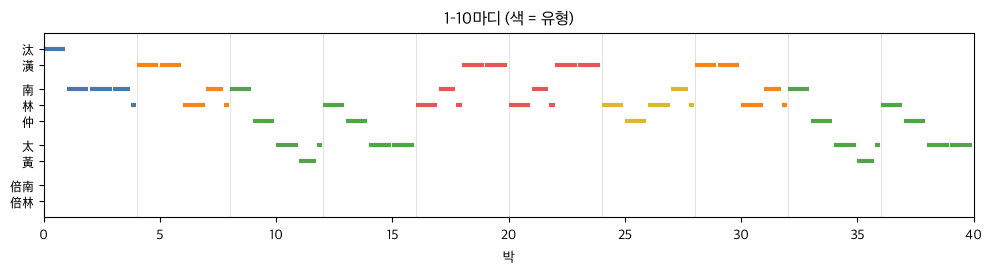

In [3]:
m1 = typ.phrases[0]
print("1마디:", [(YUL.get(p, "쉼"), d) for p, d in m1])
print("격자 토큰:", grid.encode(m1))
assert grid.decode(grid.encode(m1)) == list(m1)  # 격자 표현은 손실이 없습니다

def roll(ax, phrases, colors=None, y0=56, y1=79):
    """마디들을 이어 붙인 피아노 롤."""
    x = 0
    for k, ph in enumerate(phrases):
        for p, d in ph:
            if p is not None:
                ax.plot([x, x + d * 0.92], [p, p], lw=3, solid_capstyle="butt", color=(colors[k] if colors else "k"))
            x += d
        ax.axvline(x, color="#ddd", lw=0.6, zorder=0)
    ax.set_ylim(y0, y1); ax.set_yticks(grid.pitches); ax.set_yticklabels([YUL_PLOT[p] for p in grid.pitches]); ax.set_xlim(0, x)

fig, ax = plt.subplots(figsize=(12, 2.4))
roll(ax, typ.phrases[:10], [COLORS[l] for l in typ.labels[:10]])
ax.set_title("1–10마디 (색 = 유형)"); ax.set_xlabel("박"); plt.show()

## 2. 유형과 프레이즈 그래프

마디 사이의 거리는 길이를 가중한 **편집 거리**입니다(음 바꾸기·넣기·빼기와 한 음 ↔ 여러 음 쪼개기). 이 거리로 가중 k-medoids(k = 9)를 돌려 유형 A–I와 각 유형의 **대표 마디(medoid)** 를 얻습니다.
원곡의 유형열에서 전이 횟수를 세면 **프레이즈 그래프 G**가 됩니다.

원곡 유형열 (장별): ABCC | DDEBCC | ABEDEEFDAGHIIG | ABCC | EFFFGFGFHHIHG | AFHBBEDGDEBFFF | EIHGAFCFCFEEEHCCH
대표 마디: {'A': 1, 'B': 2, 'C': 4, 'D': 14, 'E': 15, 'F': 43, 'G': 33, 'H': 40, 'I': 39}
관측된 전이 종류: 41 / 전체 전이 수: 71


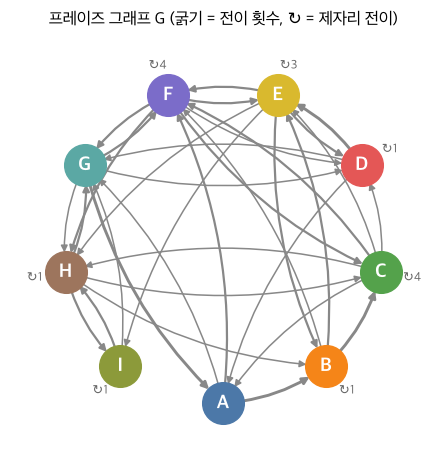

In [4]:
print("원곡 유형열 (장별):", typ.sequence_by_chapter().upper())
print("대표 마디:", {NAMES[c]: m + 1 for c, m in enumerate(typ.medoid_phrases)})
W = typ.transition_counts()
print("관측된 전이 종류:", int((W > 0).sum()), "/ 전체 전이 수:", int(W.sum()))

K = typ.k
ang = -np.pi / 2 + 2 * np.pi * np.arange(K) / K
pos = np.c_[np.cos(ang), np.sin(ang)]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for a in range(K):
    for b in range(K):
        if W[a, b] and a != b:
            ax.annotate("", pos[b] * 0.9, pos[a] * 0.9, arrowprops=dict(arrowstyle="-|>", lw=0.6 + W[a, b] * 0.5,
                        color="#888", connectionstyle="arc3,rad=0.15", shrinkA=14, shrinkB=14))
for c in range(K):
    ax.scatter(*pos[c] * 0.9, s=900, color=COLORS[c], zorder=3)
    ax.text(*pos[c] * 0.9, NAMES[c], ha="center", va="center", color="white", weight="bold", fontsize=14, zorder=4)
    if W[c, c]: ax.text(*pos[c] * 1.08, f"↻{W[c, c]}", ha="center", va="center", fontsize=9, color="#666")
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.axis("off"); ax.set_title("프레이즈 그래프 G (굵기 = 전이 횟수, ↻ = 제자리 전이)")
plt.show()

## 3. 프레이즈 다양체: 그래프에 살을 붙이기

같은 유형의 마디들은 대표 마디를 중심으로 조금씩 다르게 변주된 선율입니다. 72마디를 편집 거리가 보존되도록 평면에 펼치면(metric MDS), 유형마다 **덩어리**가 생기고 원곡은 그 덩어리들 사이를 오가는 **하나의 곡선**이 됩니다.
덩어리를 대표 마디 하나로 줄이면 2절의 그래프가 됩니다. 붉은 겹선은 1–4마디와 25–28마디가 같은 길을 두 번 지나는 **환입**입니다.

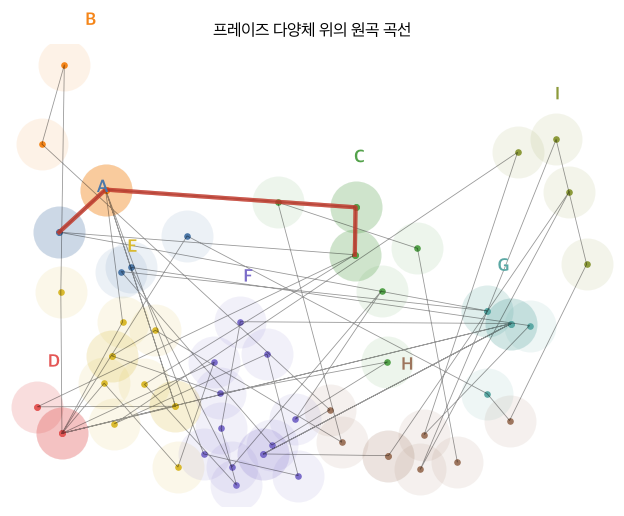

In [5]:
sys.path.insert(0, str(ROOT / "scripts"))
from export_web import smacof  # 웹 페이지와 같은 좌표
from gugakgen.chart.edit_distance import distance_matrix

D = distance_matrix([tuple(p) for p in typ.phrases])
X = np.round(smacof(D), 6)
labels = np.array(typ.labels)

def draw_manifold(ax, X, labels, curve=None, returns=((0, 4), (24, 28))):
    for c in range(K):
        P = X[labels == c]
        ax.scatter(P[:, 0], P[:, 1], s=1400, color=COLORS[c], alpha=0.10, linewidths=0)
        ax.scatter(P[:, 0], P[:, 1], s=14, color=COLORS[c])
        ax.text(P[:, 0].mean(), P[:, 1].max() + 0.25, NAMES[c], color=COLORS[c], weight="bold", ha="center", fontsize=13)
    if curve is not None:
        ax.plot(curve[:, 0], curve[:, 1], color="k", lw=0.6, alpha=0.4)
        for a, b in returns:
            ax.plot(curve[a:b, 0], curve[a:b, 1], color="#c0392b", lw=3, alpha=0.6)
    ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(9, 6))
draw_manifold(ax, X, labels, curve=X)
ax.set_title("프레이즈 다양체 위의 원곡 곡선"); plt.show()

## 4. 그래프 위의 새 유형열 Y′

새 곡의 뼈대는 G 위의 **1차 마르코프 보행**입니다. 길이 72, 첫·끝 유형은 원곡과 같고, 환입 구간(1–4 ↔ 25–28마디)은 같은 유형이어야 합니다. 이 조건들을 정확히 만족하도록 환입 구간을 먼저 뽑고 그 사이를 다리 표본(bridge sampling)으로 채웁니다.

In [6]:
rng = np.random.default_rng(0)
chapters = np.array(typ.chapters)
def by_chapter(walk):
    return " | ".join("".join(NAMES[w] for w, ch in zip(walk, chapters) if ch == c) for c in sorted(set(chapters)))
print("원곡 :", by_chapter(typ.labels))
for i in range(3):
    walk = setup["walk"].sample(rng)
    assert walk[0:4] == walk[24:28] and all(W[a, b] for a, b in zip(walk, walk[1:]))
    print(f"새 {i + 1} :", by_chapter(walk), f"(원곡과 다른 자리 {np.mean(np.array(walk) != labels):.0%})")

원곡 : ABCC | DDEBCC | ABEDEEFDAGHIIG | ABCC | EFFFGFGFHHIHG | AFHBBEDGDEBFFF | EIHGAFCFCFEEEHCCH
새 1 : ABEF | EBBEIH | IHIIGHBEBFFEED | ABEF | CEFFEIIHHHGAF | FEEHIHHGFEEHCE | BEFEHBCCCFEBCCCFH (원곡과 다른 자리 78%)
새 2 : ABCC | EDGABE | IHIHGFHIHIHGFG | ABCC | FGHBEIIGHIIGH | IIHCFHCDEIGFFC | FCFFHBEBCCHHCCHGH (원곡과 다른 자리 75%)
새 3 : ABCC | CDEFFE | EFFHGDEHCCHBFG | ABCC | FCCAFEFHBFCCC | CHIHCFHGAGABFG | FHIHIGAFGABFFFEHH (원곡과 다른 자리 78%)


## 5. 마스크형(흡수 상태) 이산 확산

앞 과정은 단순합니다. 시간 r ∈ (0, 1]에서 각 칸을 확률 r로 `MASK`(■)로 바꿉니다. r = 1이면 마디 전체가 가려집니다.
모형은 가려진 칸의 원래 토큰을 맞히도록 학습하고, 생성할 때는 모두 가린 상태에서 시작해 조금씩 드러냅니다.

In [7]:
from gugakgen.chart.diffusion import corrupt
rows = v1.to_device(setup["rows"], torch.device("cpu"))
one = {k: v[:1] for k, v in rows.items()}
sym = lambda t: "■" if t == grid.mask else ("~" if t == grid.hold else ("·" if t == grid.on_rest else YUL[grid.pitches[t]]))
g = torch.Generator().manual_seed(1)
for r in (0.0, 0.3, 0.6, 1.0):
    noisy, _ = corrupt(one, torch.tensor([r]), g, grid.mask)
    print(f"r = {r:.1f}  ", " ".join(sym(int(t)) for t in noisy["tokens"][0][: one["length"][0]]))
print("(~ = 앞 음 이어짐)")

r = 0.0   汰 ~ ~ ~ 南 ~ ~ ~ 南 ~ ~ ~ 南 ~ ~ 林
r = 0.3   汰 ~ ~ ~ ■ ~ ~ ~ 南 ■ ■ ■ 南 ~ ~ ■
r = 0.6   ■ ■ ■ ■ 南 ■ ~ ~ ■ ■ ~ ~ ■ ~ ~ 林
r = 1.0   ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
(~ = 앞 음 이어짐)


## 6. 모형과 손실, 그리고 학습

**모형**은 작은 Transformer(3층, 폭 96, 약 23만 개 변수)입니다. 한 마디의 칸들과 함께 다음 조건을 받습니다.
- 이 자리의 유형, 앞뒤 마디의 유형;
- 앞뒤 마디의 경계 음;
- 그 유형 **대표 마디의 선율 윤곽**(길이에 맞춰 늘림).

**손실** L = L_diff + λ · L_graph
- L_diff: 원곡 72마디에 대한 확산 ELBO(가려진 칸의 교차 엔트로피를 1/r로 가중).
- L_graph: 원곡에 없는 **새 유형열**을 조건으로 주고 모두 가린 입력의 예측에서 유형 전이를 부드럽게 다시 읽어, 조건 유형열의 전이와의 총변동 거리를 벌점으로 줍니다. 자료가 없는 점에서 계산하는 PINN의 collocation 손실과 같은 발상입니다.

논문 설정 그대로 λ = 0과 λ = 0.5를 125 step씩 학습해 봅니다(CPU에서 각각 약 10초, 40초).

변수 수: 236363


λ = 0.0: 7초, 마지막 L_diff = 0.476


λ = 0.5: 34초, 마지막 L_diff = 0.438, L_graph = 0.077


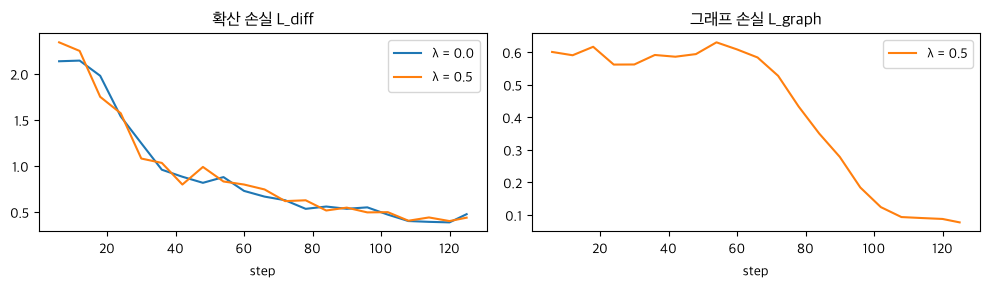

In [8]:
from gugakgen.chart.diffusion import GridDenoiser
from gugakgen.device import resolve_device
import time

runtime = resolve_device("cpu")
print("변수 수:", sum(p.numel() for p in GridDenoiser(layout, **setup["config"]["model"]).parameters()))
models = {}
for lam in (0.0, 0.5):
    t0 = time.time()
    model, tables, history = v1.train_model(setup, {"lambda_graph": lam}, range(72), 260807, 125, runtime)
    models[lam] = (model, tables, history)
    print(f"λ = {lam}: {time.time() - t0:.0f}초, 마지막 L_diff = {history[-1]['diffusion']:.3f}"
          + (f", L_graph = {history[-1]['graph']:.3f}" if "graph" in history[-1] else ""))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for lam, (_, _, h) in models.items():
    axes[0].plot([x["step"] for x in h], [x["diffusion"] for x in h], label=f"λ = {lam}")
    if "graph" in h[-1]:
        axes[1].plot([x["step"] for x in h], [x["graph"] for x in h], color="C1", label=f"λ = {lam}")
axes[0].set(title="확산 손실 L_diff", xlabel="step"); axes[1].set(title="그래프 손실 L_graph", xlabel="step")
axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()

## 7. 곡 생성

`generate_piece`는 (1) G 위에서 새 유형열을 뽑고, (2) 72마디를 모두 가린 상태에서 24단계에 걸쳐 칸을 드러내며, (3) 환입 두 구간은 **한 변수로 묶어** 함께 뽑습니다. 그 뒤 대표 마디 기준으로 조건 유형에 속하지 않는 마디만 골라 최대 4번 다시 생성합니다.
'재생성 전 유형 소속'은 이 재생성 전에 이미 조건 유형을 따른 마디의 비율입니다. 구조 손실(λ > 0)이 이 값을 높입니다.

λ = 0.0: 재생성 전 유형 소속 84%, 최종 100%, 원곡 마디와 같은 마디 18%, 환입 일치 True


λ = 0.5: 재생성 전 유형 소속 91%, 최종 100%, 원곡 마디와 같은 마디 24%, 환입 일치 True
유형열: ABEF | HIGAGA | FGDDDDEEEIIHIG | ABEF | DEBBCCHHGDDAB | EDEBEBCFFHHIGD | EHGFCCCCFEIHHIHGH


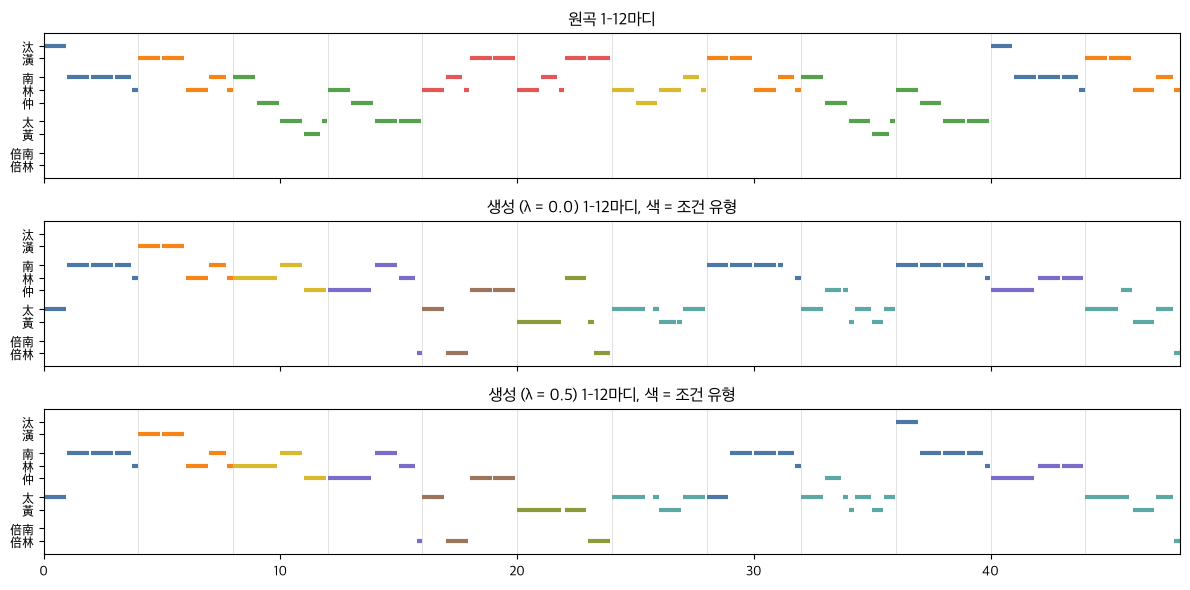

In [9]:
pieces = {}
for lam, (model, tables, _) in models.items():
    phrases, walk, first_pass = v1.generate_piece(model, tables, setup, seed=7)
    m = v1.piece_metrics(phrases, walk, setup, first_pass)
    pieces[lam] = (phrases, walk)
    print(f"λ = {lam}: 재생성 전 유형 소속 {m['first_pass_membership']:.0%}, 최종 {m['membership']:.0%}, "
          f"원곡 마디와 같은 마디 {m['original_phrase_rate']:.0%}, 환입 일치 {bool(m['returns_exact'])}")
print("유형열:", by_chapter(walk))

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
roll(axes[0], typ.phrases[:12], [COLORS[l] for l in typ.labels[:12]]); axes[0].set_title("원곡 1–12마디")
for ax, (lam, (ph, w)) in zip(axes[1:], pieces.items()):
    roll(ax, ph[:12], [COLORS[t] for t in w[:12]]); ax.set_title(f"생성 (λ = {lam}) 1–12마디, 색 = 조건 유형")
plt.tight_layout(); plt.show()

생성한 곡을 다양체 위에 올려 봅니다. 새 마디는 가장 가까운 원곡 마디들과의 편집 거리를 맞추도록 배치합니다(웹 페이지와 같은 규칙).

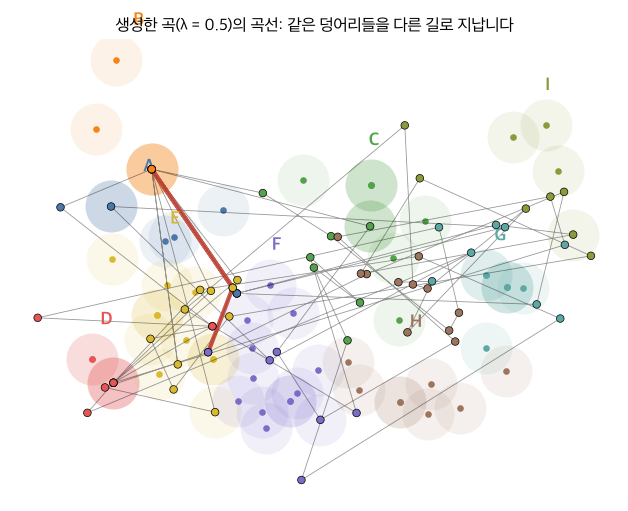

In [10]:
from export_web import project
from gugakgen.chart.edit_distance import distance
phrases, walk = pieces[0.5]
Y = np.array([project(np.array([distance(p, o) for o in typ.phrases]), X) for p in phrases])
fig, ax = plt.subplots(figsize=(9, 6))
draw_manifold(ax, X, labels, curve=Y)
ax.scatter(Y[:, 0], Y[:, 1], c=[COLORS[t] for t in walk], s=30, edgecolors="k", linewidths=0.5, zorder=5)
ax.set_title("생성한 곡(λ = 0.5)의 곡선: 같은 덩어리들을 다른 길로 지납니다"); plt.show()

악보(MusicXML)로 내보내고 Verovio로 그려 봅니다. 다음 칸에서는 첫 8마디를 간단한 합성음으로 들어 봅니다.

저장: tutorial_outputs/tutorial_lambda05_s260807_piece7.musicxml


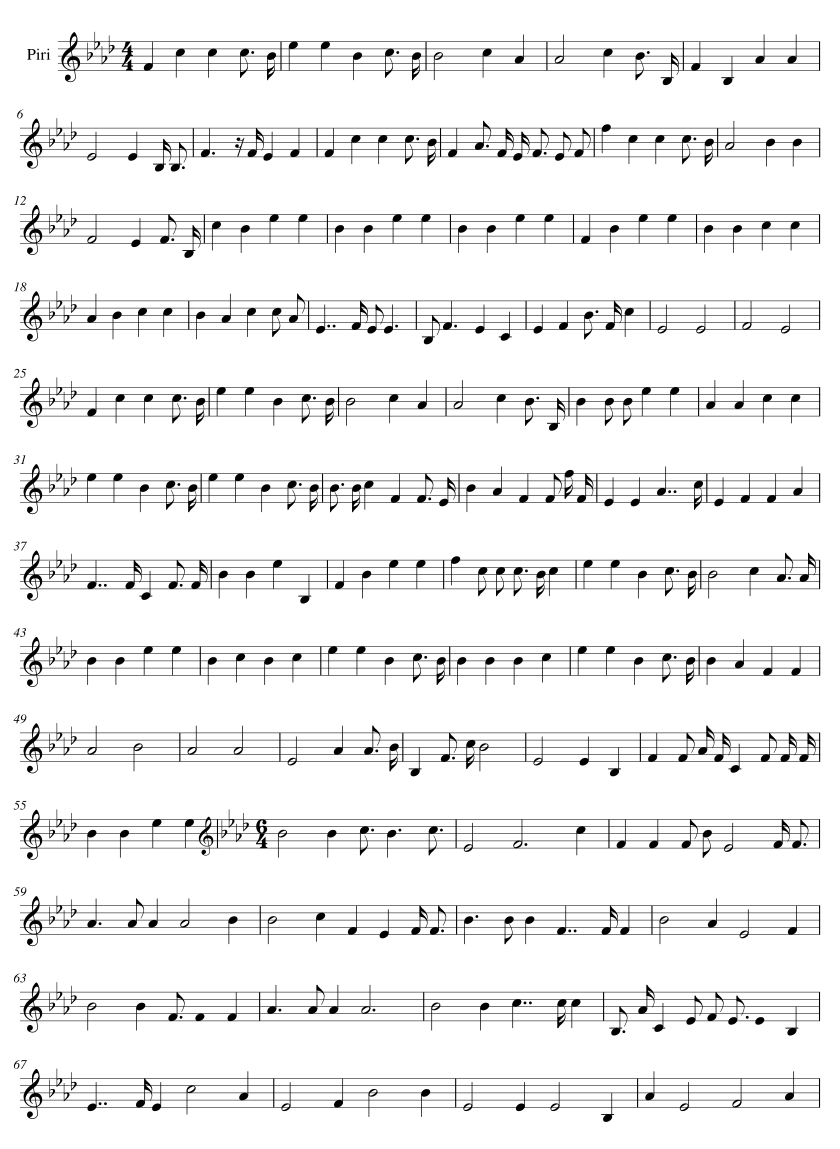

In [11]:
out = ROOT / "tutorial_outputs"; out.mkdir(exist_ok=True)
unit = {"arm": "tutorial_lambda05", "seed": 260807, "generation": {"pieces": [
    {"seed": 7, "walk": walk, "phrases": [[[p, d] for p, d in ph] for ph in phrases]}]}}
for f in out.glob("tutorial_lambda05_*.musicxml"): f.unlink()  # 다시 실행할 때를 위해
[xml_path] = v1.export_musicxml(unit, setup, out, count=1)
print("저장:", xml_path.relative_to(ROOT))
try:
    import verovio
    from IPython.display import SVG, display
    tk = verovio.toolkit()
    tk.setOptions({"pageWidth": 2100, "scale": 40, "adjustPageHeight": True, "breaks": "auto", "header": "none", "footer": "none"})
    tk.loadData(xml_path.read_text(encoding="utf-8"))
    display(SVG(tk.renderToSVG(1)))
except ImportError:
    print("pip install verovio 후 악보가 그려집니다.")

In [ ]:
# 첫 8마디 듣기 (♩ = 66, 브라우저 합성음; 피리 녹음이 아닙니다)
from IPython.display import Audio
def synth(phrases, bpm=66, sr=16000):
    out, spb = [], 60 / bpm
    for ph in phrases:
        for p, d in ph:
            n = int(d * spb * sr); t = np.arange(n) / sr
            if p is None: out.append(np.zeros(n)); continue
            f = 440 * 2 ** ((p - 69) / 12) * (1 + 0.004 * np.sin(2 * np.pi * 5 * t) * (t > 0.2))
            ph_ = 2 * np.pi * np.cumsum(f) / sr
            tone = sum(np.sin(k * ph_) / k for k in range(1, 7))
            env = np.minimum(1, t / 0.03) * np.minimum(1, (n / sr - t) / 0.04)
            out.append(0.25 * tone * env)
    return np.concatenate(out)
Audio(synth(phrases[:8]), rate=16000)

## 8. 논문 결과 재현 확인

저장소에는 논문 그림 12(λ 실험)에 쓴 모형 중 학습 Seed 260807의 체크포인트가 들어 있습니다(`results/checkpoints/`).
- 논문 체크포인트로 같은 Seed의 곡을 생성하면 논문 실행의 곡과 **똑같은 곡**이 나옵니다.
- 같은 Seed로 다시 학습하면, 저자 환경(Apple M1 CPU, PyTorch 2.15, 기본 스레드 수)에서는 변수가 **비트 단위로 같습니다**. CPU 스레드 수나 PyTorch 판, GPU 사용 여부가 다르면 1e-3 정도의 작은 차이가 날 수 있습니다(덧셈 순서 차이).

In [13]:
import json
RUN = "20261113_1653_cpu_lambda_sweep"
ck = torch.load(ROOT / f"results/checkpoints/{RUN}/full_diffusion_s260807.pt", map_location="cpu", weights_only=False)
retrained, tables, _ = models[0.0]  # 6절에서 λ = 0, Seed 260807, 125 step으로 학습한 모형
diff = max((retrained.state_dict()[k] - v).abs().max().item() for k, v in ck["state_dict"].items())
print(f"다시 학습한 모형과 논문 체크포인트의 최대 변수 차이: {diff:.2e} (스레드 {torch.get_num_threads()}개)")

paper = GridDenoiser(layout, **setup["config"]["model"]); paper.load_state_dict(ck["state_dict"]); paper.eval()
report = json.loads((ROOT / f"results/runs/{RUN}/report_slim.json").read_text(encoding="utf-8"))
unit = next(u for u in report["full"] if u["arm"] == "diffusion" and u["seed"] == 260807)
target = unit["generation"]["pieces"][0]
phrases, walk, _ = v1.generate_piece(paper, tables, setup, target["seed"])
same = walk == target["walk"] and [list(map(list, p)) for p in phrases] == [[[e[0], e[1]] for e in p] for p in target["phrases"]]
print("논문 실행의 곡", target["seed"], "을 그대로 다시 생성:", same)

다시 학습한 모형과 논문 체크포인트의 최대 변수 차이: 0.00e+00 (스레드 4개)


논문 실행의 곡 260807 을 그대로 다시 생성: True


마지막으로 논문의 핵심 결과입니다. λ를 키우면 마디가 조건 유형을 더 잘 따르지만(왼쪽), 학습 마디에 가까운 선율도 늘어 복제 검정 Z가 −2 아래로 내려갑니다(가운데). 〈양청도드리〉에서는 λ ≈ 0.1까지가 복제 검정 기준 안에 머물렀습니다. 이 그림은 `python figures/make_all.py`로 `results/runs`에서 다시 만들 수 있습니다.

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "figures/output/f15_lambda_sweep.png"), width=900))

## 다음 단계

- **전체 실험 다시 돌리기**: `experiments/chart_diffusion_colab.ipynb` (보류 학습 길이 선택, 60곡 생성, 복제 검정, 평가까지). 결과는 `artifacts/chart_diffusion_runs/<RUN_TAG>/`에 쓰이고 기존 결과는 덮어쓰지 않습니다.
- **논문 그림 다시 만들기**: `python figures/make_all.py` (`figures/README.md`에 그림 ↔ 실행 대응표).
- **웹에서 직접 생성해 보기**: [GitHub Pages](https://shlee-tda.github.io/DiffDodree/) — 같은 모형을 ONNX로 브라우저에서 돌립니다.